# 04: Window features and gradient boosting

Study levels 3 and 4. Notebook 03 left a linear model on raw sensor readings at RMSE 25.0 (mean over 30 cut draws) and a diagnosis: its problem is bias, not variance. A straight line through a single noisy reading cannot follow a degradation that accelerates. This notebook fixes both halves: features that describe the trajectory, and a model that can bend.

Questions, each answered by one section and collected in the Decisions cell at the end:

1. Which window features carry signal, and which are copies of each other?
2. How much does LightGBM gain over the linear model on the same features, and is the gain beyond the protocol's noise?
3. Do the regularization knobs matter on FD001? Does the loss?
4. What does the model rely on, and can the feature set be pruned?
5. Why does the model predict what it predicts for one engine?

Everything is scored under the notebook 03 protocol: engine-wise folds, cut points, RMSE and PHM08 per 100 predictions, mean over 30 draws with per-fold scores. Theory is in `docs/learning/03-time-series-features.md` and `04-gradient-boosting.md`.

## 1. Building the features

The feature code lives in `src/turbofan_rul/features.py` and is covered by tests, including one that checks every feature at cycle $t$ is unchanged when later cycles are removed. Per sensor: trailing means over 5, 10 and 30 cycles, the difference between the current reading and the 30-cycle mean, slopes over 10 and 30 cycles, the 30-cycle standard deviation, and the deviation of the 5-cycle mean from the engine's own baseline (its first 20 cycles). Sensors 9 and 14 enter only as absolute deviations, because their trend sign differs by engine (notebook 01). Plus age.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from turbofan_rul.config import FD001_RAW_SENSORS as SENSORS
from turbofan_rul.config import N_FOLDS, RUL_CAP
from turbofan_rul.data_loading import add_rul_labels, load_subset
from turbofan_rul.evaluation import phm08_per_100, summarize
from turbofan_rul.features import build_features, feature_columns
from turbofan_rul.validation import engine_folds, sample_cut_points

df = add_rul_labels(load_subset("FD001", split="train"))
folds = engine_folds(df)
df["fold"] = df["unit"].map(folds)
lifetimes = df.groupby("unit")["cycle"].max()

t0 = time.perf_counter()
X = build_features(df)
FEATURES = feature_columns(X)
print(f"{len(FEATURES)} features for {len(X):,} rows in {time.perf_counter() - t0:.1f} s")
pd.Series(FEATURES).str.extract(r"_(mean\d+|diff\d+|slope\d+|std\d+|absdev|dev)$")[0].fillna("age").value_counts().rename("features per family")

99 features for 20,631 rows in 0.8 s


0
mean5      12
mean10     12
mean30     12
diff30     12
slope10    12
slope30    12
std30      12
dev        12
absdev      2
age         1
Name: features per family, dtype: int64

### 1a. Why the trajectory, and not the reading or its difference

Two numbers from level 3 explain the design. The lag-1 autocorrelation within an engine says how much a new cycle adds to the previous one. The first difference says what is left once the trend is removed.

In [2]:
def lag1(s):
    return s.autocorr(1)

acf = pd.DataFrame({
    "raw reading": X.groupby("unit")["sensor_4"].apply(lag1),
    "30-cycle mean": X.groupby("unit")["sensor_4_mean30"].apply(lag1),
    "first difference": X.groupby("unit")["sensor_4"].apply(lambda s: s.diff().autocorr(1)),
}).mean().rename("mean lag-1 autocorrelation within an engine, sensor 4")
acf.round(2)

raw reading         0.74
30-cycle mean       1.00
first difference   -0.50
Name: mean lag-1 autocorrelation within an engine, sensor 4, dtype: float64

**Reading.** The raw reading of sensor 4 has a lag-1 autocorrelation of 0.74: consecutive cycles mostly repeat each other, and 20,631 rows are far fewer independent observations than their count. The 30-cycle mean has autocorrelation 1.00, so smoothing makes neighbouring rows even more alike, which is what the row-wise split exploited in notebook 03. The first difference has −0.50, the signature of noise followed by its correction: differencing removes the trend, and here the trend is the signal. The features therefore measure the trend over windows (slopes, deviations) instead of removing it.

## 2. Which features carry signal

The linear model from notebook 03, now on the raw readings plus one feature family at a time, under the protocol. The linear model is the probe here because it cannot build non-linearities on its own: whatever it gains comes from the feature. Scores are means over 30 cut draws.

In [3]:
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

rows = X[["unit", "cycle", "fold", "rul"]].copy()
rows["rul_true"] = lifetimes.loc[rows["unit"]].to_numpy() - rows["cycle"].to_numpy()


def oof_rows(make_model, features, data=X):
    # Out-of-fold predictions for every training row: train on four folds, predict the fifth.
    pred = np.full(len(data), np.nan)
    for f in range(N_FOLDS):
        train, hold = data[data["fold"] != f], data["fold"] == f
        model = make_model().fit(train[features], train["rul"])
        pred[hold.to_numpy()] = model.predict(data.loc[hold, features])
    return np.clip(pred, 0, RUL_CAP)


def score_draws(pred, n_draws=30):
    # Mean and std over cut draws, plus per-fold RMSE on the seed-0 draw.
    table = rows.assign(pred=pred)
    draws = []
    for seed in range(n_draws):
        c = sample_cut_points(df, seed=seed).merge(table, on=["unit", "cycle"], suffixes=("", "_row"))
        draws.append({"rmse": summarize(c["rul_true"], c["pred"])["rmse"],
                      "phm08_per_100": phm08_per_100(c["rul_true"], c["pred"])})
    draws = pd.DataFrame(draws)
    c0 = sample_cut_points(df, seed=0).merge(table, on=["unit", "cycle"], suffixes=("", "_row"))
    per_fold = c0.groupby("fold").apply(lambda g: summarize(g["rul_true"], g["pred"])["rmse"], include_groups=False)
    return {"rmse": draws["rmse"].mean(), "rmse_std": draws["rmse"].std(),
            "phm08_per_100": draws["phm08_per_100"].mean(), "fold_min": per_fold.min(), "fold_max": per_fold.max()}


linear = lambda: make_pipeline(StandardScaler(), LinearRegression())
fam = lambda suffix: [c for c in FEATURES if c.endswith(suffix)]
feature_sets = {
    "raw readings": SENSORS,
    "raw + 5-cycle mean": SENSORS + fam("_mean5"),
    "raw + 30-cycle mean": SENSORS + fam("_mean30"),
    "raw + diff from 30-cycle mean": SENSORS + fam("_diff30"),
    "raw + 10-cycle slope": SENSORS + fam("_slope10"),
    "raw + 30-cycle slope": SENSORS + fam("_slope30"),
    "raw + 30-cycle std": SENSORS + fam("_std30"),
    "raw + deviation from baseline": SENSORS + fam("_dev"),
    "raw + |deviation| of sensors 9, 14": SENSORS + fam("_absdev"),
    "raw + age": SENSORS + ["age"],
    "all features": FEATURES,
}
Xf = X.fillna(0)  # linear models cannot take NaN; incomplete windows become 0 (never evaluated: min history is 30)
linear_results = pd.DataFrame({name: score_draws(oof_rows(linear, cols, Xf)) for name, cols in feature_sets.items()}).T
linear_results["n_features"] = [len(c) for c in feature_sets.values()]
linear_results.round(1)

,rmse,rmse_std,phm08_per_100,fold_min,fold_max,n_features
raw readings,25.0,0.4,1708.9,22.1,26.4,12
raw + 5-cycle mean,24.0,0.4,1413.0,20.7,27.2,24
raw + 30-cycle mean,23.1,0.4,1272.7,21.1,24.8,24
raw + diff from 30-cycle mean,23.1,0.4,1272.7,21.1,24.8,24
raw + 10-cycle slope,24.2,0.4,1515.7,21.9,25.6,24
raw + 30-cycle slope,19.5,0.3,679.8,17.4,19.5,24
raw + 30-cycle std,23.8,0.4,1381.2,21.3,25.0,24
raw + deviation from baseline,20.0,0.3,713.7,17.9,20.6,24
"raw + |deviation| of sensors 9, 14",24.0,0.4,1388.4,22.3,25.4,14
raw + age,24.2,0.3,1342.1,21.6,25.7,13


In [4]:
ridge = lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-1, 4, 20)))
linear_results.loc["all features, ridge"] = {**score_draws(oof_rows(ridge, FEATURES, Xf)), "n_features": len(FEATURES)}
linear_results.loc[["all features", "all features, ridge"]].round(1)

,rmse,rmse_std,phm08_per_100,fold_min,fold_max,n_features
all features,19.3,0.4,659.7,17.6,20.1,99
"all features, ridge",19.2,0.4,651.8,17.5,20.1,99


**Reading.** The feature families separate into three groups, and the gap between them is far beyond the protocol's noise (about 0.4 of draw-to-draw spread, about 2 fold-to-fold).

- **Trend features carry the signal.** The 30-cycle slope takes the linear model from 25.0 to 19.5 and cuts PHM08 by 60%; the deviation from the engine's own baseline does almost as much (20.0). Both describe where the engine is going, not where it is.
- **Level features add a little.** Means, the difference from the mean and the rolling std each gain 1 to 2 cycles. The 10-cycle slope gains less than 1: too noisy to measure a trend (level 3, 3.4). "Raw + 30-cycle mean" and "raw + difference from it" score identically, as they must for a linear model (level 3, 3.3).
- **Age and sensors 9 and 14 do little for a linear model**, 1 cycle each. Their value is non-linear and shows up in section 4.

All 99 features together give 19.3, barely better than the slope alone, and ridge gives 19.2: still no variance to remove, with 16,000 rows behind 99 coefficients (level 3, 3.7). The linear model has hit its ceiling. What remains is bias, and that needs a model that can bend.

## 3. LightGBM under the protocol

Gradient boosting on all 99 features. Inside each fold, the 80 training engines are split again by engine: 64 to fit the trees, 16 to monitor the loss for early stopping (patience 100). The validation engines of the fold never touch training. Settings (in `config.py`): learning rate 0.03, 15 leaves, at least 50 rows per leaf, 80% row and column subsampling per tree.

In [5]:
import lightgbm as lgb

from turbofan_rul.config import EARLY_STOPPING_ROUNDS, LGBM_PARAMS, MONITOR_ENGINES


def oof_rows_lgbm(features, early_stopping=True, fold_col="fold", **overrides):
    # Row-level out-of-fold predictions. With early stopping, 16 of the 80 training engines monitor the loss.
    params = {**LGBM_PARAMS, **overrides}
    pred, best = np.full(len(X), np.nan), []
    for f in range(N_FOLDS):
        train, hold = X[X[fold_col] != f], (X[fold_col] == f).to_numpy()
        model = lgb.LGBMRegressor(**params)
        if early_stopping:
            monitor_units = np.random.default_rng(f).choice(train["unit"].unique(), size=MONITOR_ENGINES, replace=False)
            is_monitor = train["unit"].isin(monitor_units)
            model.fit(train.loc[~is_monitor, features], train.loc[~is_monitor, "rul"],
                      eval_X=train.loc[is_monitor, features], eval_y=train.loc[is_monitor, "rul"],
                      callbacks=[lgb.early_stopping(EARLY_STOPPING_ROUNDS, verbose=False)])
            best.append(model.best_iteration_)
        else:
            model.fit(train[features], train["rul"])
            best.append(params["n_estimators"])
        pred[hold] = model.predict(X.loc[hold, features])
    return np.clip(pred, 0, RUL_CAP), best


t0 = time.perf_counter()
pred_lgbm, best_iters = oof_rows_lgbm(FEATURES)
print(f"early stopping chose {best_iters} trees per fold, {time.perf_counter() - t0:.0f} s")
pred_lgbm_raw, _ = oof_rows_lgbm(SENSORS)
pred_lgbm_fixed, _ = oof_rows_lgbm(FEATURES, early_stopping=False)

results = pd.DataFrame({
    "linear, raw readings": linear_results.loc["raw readings"].drop("n_features"),
    "linear, all features": linear_results.loc["all features"].drop("n_features"),
    "LightGBM, raw readings": score_draws(pred_lgbm_raw),
    "LightGBM, all features, early stopping": score_draws(pred_lgbm),
    "LightGBM, all features, 2000 trees": score_draws(pred_lgbm_fixed),
}).T
results.round(1)

early stopping chose [1361, 1968, 1726, 574, 1490] trees per fold, 24 s


,rmse,rmse_std,phm08_per_100,fold_min,fold_max
"linear, raw readings",25.0,0.4,1708.9,22.1,26.4
"linear, all features",19.3,0.4,659.7,17.6,20.1
"LightGBM, raw readings",24.8,0.5,2462.9,22.2,26.0
"LightGBM, all features, early stopping",12.7,0.3,238.8,10.7,13.1
"LightGBM, all features, 2000 trees",12.4,0.4,228.0,10.5,12.4


In [6]:
# Where each model errs, by true remaining life at the cut (seed-0 draw)
c0 = sample_cut_points(df, seed=0).merge(rows.assign(linear=oof_rows(linear, FEATURES, Xf), lgbm=pred_lgbm), on=["unit", "cycle"], suffixes=("", "_row"))
bins = pd.cut(c0["rul_true"], [0, 25, 50, 75, 100, 125, 150])
by_bin = pd.DataFrame({
    (m, stat): (c0[m] - c0["rul_true"]).groupby(bins, observed=True).agg(stat)
    for m in ["linear", "lgbm"] for stat in ["mean", "std"]
})
by_bin.columns = ["linear mean error", "linear spread", "LightGBM mean error", "LightGBM spread"]
by_bin.round(1)

,linear mean error,linear spread,LightGBM mean error,LightGBM spread
rul_true,,,,
"(0, 25]",2.1,10.9,0.4,3.1
"(25, 50]",16.7,14.0,2.5,7.2
"(50, 75]",15.6,12.8,4.4,9.9
"(75, 100]",6.8,14.4,5.5,13.6
"(100, 125]",-7.7,13.4,-2.3,10.4
"(125, 150]",-27.5,10.8,-21.0,8.3


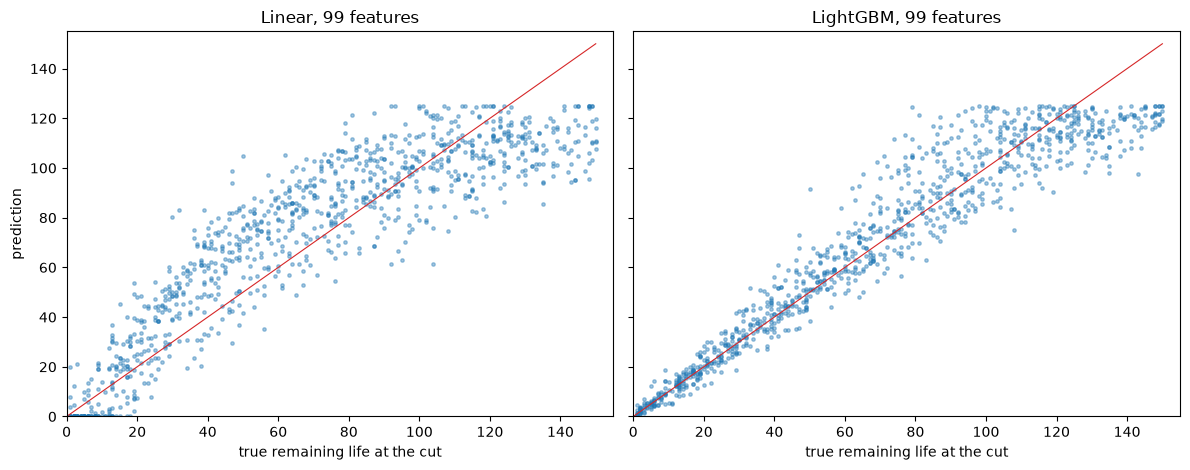

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, col, title in [(axes[0], "linear", "Linear, 99 features"), (axes[1], "lgbm", "LightGBM, 99 features")]:
    ax.scatter(c0["rul_true"], c0[col], s=6, alpha=0.4)
    ax.plot([0, 150], [0, 150], color="C3", lw=0.8)
    ax.set(xlabel="true remaining life at the cut", title=title, xlim=(0, 155), ylim=(0, 155))
axes[0].set_ylabel("prediction")
plt.tight_layout()
plt.show()

**Reading.** LightGBM on the 99 features scores RMSE 12.7 and PHM08 239 per 100 predictions, against 19.3 and 660 for the linear model on the same features and 25.0 and 1,709 for the linear model on raw readings. The gap to the linear model is more than three times the fold-to-fold spread. On raw readings alone, LightGBM scores 24.8: the same as the linear model. Trees fix the shape of the relationship, but a single noisy reading has no shape to extract. The features carry the information; the model extracts it.

The error table shows the bias is gone. Between 25 and 75 cycles from failure, where the linear model was 16 to 17 cycles late, LightGBM is 2 to 4 cycles late, and in the last 25 cycles its spread is 3 cycles against 11. The scatter is a tight band along the diagonal up to the cap. Above 125 both models fail by construction of the label, as every capped model does under this protocol.

Early stopping chose between 574 and 1,968 trees across folds and scored 12.7; a fixed 2,000 trees with all 80 engines scored 12.4. At this learning rate the monitor curve is flat, and the 16 engines held out to monitor cost more than the stopping gains. The open question from the study sheet stands: keep early stopping as a guard, or refit on all 80 engines with the chosen number of trees.

### 3a. Knobs, loss and leak

Three questions in one table. Do the regularization knobs matter on FD001? Does the loss? And how much would a row-wise split inflate the score (notebook 03, section 4, now for boosting)?

In [8]:
X["row_fold"] = np.random.default_rng(0).integers(0, N_FOLDS, len(X))
variants = {
    "15 leaves / 50 per leaf (base)": {},
    "63 leaves / 5 per leaf": {"num_leaves": 63, "min_child_samples": 5},
    "7 leaves / 200 per leaf": {"num_leaves": 7, "min_child_samples": 200},
    "Huber loss": {"objective": "huber"},
}
variant_results = {}
for name, overrides in variants.items():
    pred = pred_lgbm if not overrides else oof_rows_lgbm(FEATURES, **overrides)[0]
    variant_results[name] = {**score_draws(pred), "mean_error": float(np.nanmean(pred - rows["rul"]))}
leak_pred, _ = oof_rows_lgbm(FEATURES, early_stopping=False, fold_col="row_fold", n_estimators=400)
variant_results["base, split by ROW (leak)"] = {**score_draws(leak_pred), "mean_error": float(np.nanmean(leak_pred - rows["rul"]))}
pd.DataFrame(variant_results).T.round(1)

,rmse,rmse_std,phm08_per_100,fold_min,fold_max,mean_error
15 leaves / 50 per leaf (base),12.7,0.3,238.8,10.7,13.1,-0.4
63 leaves / 5 per leaf,13.1,0.3,262.2,11.1,13.4,-0.2
7 leaves / 200 per leaf,12.9,0.4,245.6,10.5,13.5,-0.4
Huber loss,17.6,0.4,567.3,15.6,18.8,3.7
"base, split by ROW (leak)",10.1,0.3,140.2,8.3,10.5,-0.1


**Reading.** The knobs barely matter: 63 leaves with 5 rows per leaf and 7 leaves with 200 give 13.1 and 12.9, inside the noise of the 12.7 base. With 100 engines and a clean signal, there is little to tune. The loss matters a lot: the Huber objective scores 17.6, and its mean error moves from −0.4 to +3.7 cycles, late. Huber caps the gradient of large residuals, and here the large residuals are the engines near failure, the ones that matter most (level 4, 4.5). That is the opening of notebook 05.

The row-wise split inflates LightGBM from 12.7 to 10.1. Smaller than the nearest-neighbour leak in notebook 03 (25.9 to 6.4), because leaves of at least 50 rows mix engines and each tree sees a different 80% of rows, but it is there. A reported 10.1 on FD001 would be a reason to check the split.

## 4. What the model relies on

Three views of importance, computed on fold 0: gain (what the trees used while being built), permutation on the fold's validation cuts (what the model depends on to predict new engines), and mean absolute SHAP on the same cuts. Level 4, 4.6 and 4.7, say why they disagree.

In [9]:
import shap
from sklearn.inspection import permutation_importance

train0 = X[X["fold"] != 0]
model0 = lgb.LGBMRegressor(**{**LGBM_PARAMS, "n_estimators": int(np.mean(best_iters))}).fit(train0[FEATURES], train0["rul"])
cuts0 = c0[c0["fold"] == 0].merge(X[["unit", "cycle"] + FEATURES], on=["unit", "cycle"])

gain = pd.Series(model0.booster_.feature_importance("gain"), index=FEATURES)
gain = gain / gain.sum()
perm = permutation_importance(model0, cuts0[FEATURES], cuts0["rul_true"], n_repeats=10, random_state=0,
                              scoring="neg_root_mean_squared_error")
perm = pd.Series(perm.importances_mean, index=FEATURES)
shap_values = shap.TreeExplainer(model0).shap_values(cuts0[FEATURES])
shap_mean = pd.Series(np.abs(shap_values).mean(axis=0), index=FEATURES)

importance = pd.DataFrame({"gain share": gain, "permutation (RMSE increase)": perm, "mean |SHAP| (cycles)": shap_mean})
importance["rank gain"] = importance["gain share"].rank(ascending=False).astype(int)
importance["rank permutation"] = importance["permutation (RMSE increase)"].rank(ascending=False).astype(int)
importance["rank SHAP"] = importance["mean |SHAP| (cycles)"].rank(ascending=False).astype(int)
importance.sort_values("permutation (RMSE increase)", ascending=False).head(12).round(3)

/Users/alexmunozestornell/Documents/Personal_Projects/turbofan-rul/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,gain share,permutation (RMSE increase),mean |SHAP| (cycles),rank gain,rank permutation,rank SHAP
age,0.021,7.527,6.499,7,1,3
sensor_14_absdev,0.021,3.711,4.320,9,2,5
sensor_9_absdev,0.021,3.629,3.872,8,3,6
sensor_11_dev,0.285,3.116,7.221,1,4,1
sensor_15_dev,0.203,1.999,6.855,2,5,2
sensor_7_dev,0.148,1.749,4.692,3,6,4
sensor_8_dev,0.008,1.372,2.100,18,7,11
sensor_13_dev,0.010,1.246,2.365,13,8,9
sensor_12_dev,0.054,1.064,3.807,4,9,7
sensor_20_dev,0.028,0.717,2.619,6,10,8


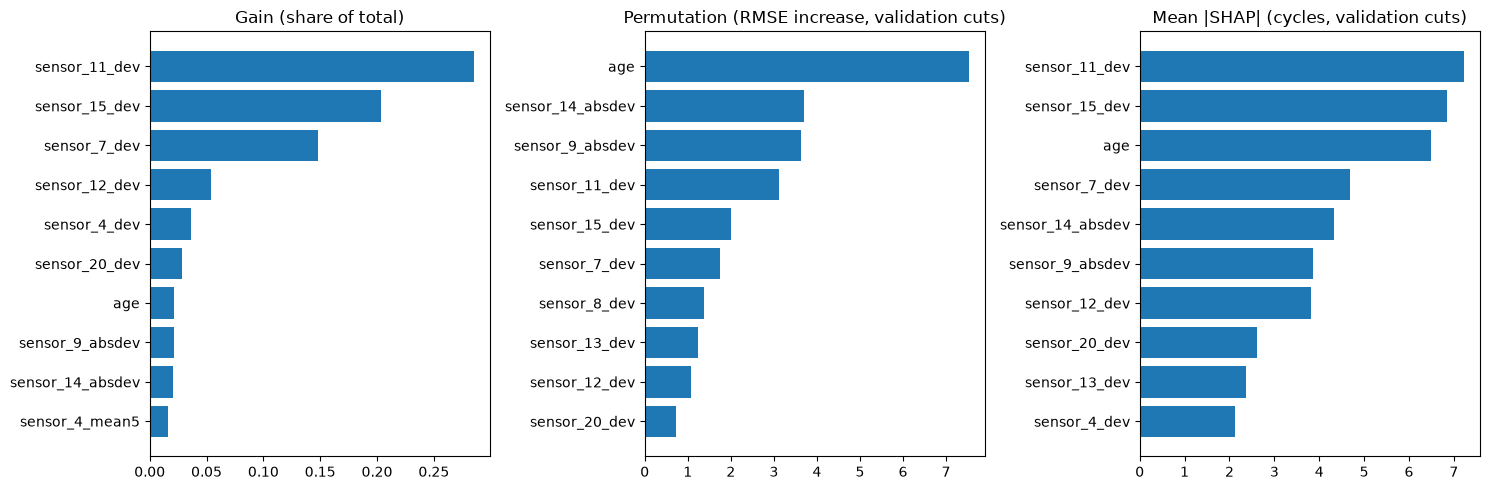

features with permutation importance below 0.05 cycles: 59 of 99


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, col, title in [(axes[0], "gain share", "Gain (share of total)"),
                       (axes[1], "permutation (RMSE increase)", "Permutation (RMSE increase, validation cuts)"),
                       (axes[2], "mean |SHAP| (cycles)", "Mean |SHAP| (cycles, validation cuts)")]:
    top = importance[col].nlargest(10)[::-1]
    ax.barh(top.index, top.values)
    ax.set(title=title)
plt.tight_layout()
plt.show()

print(f"features with permutation importance below 0.05 cycles: {(perm < 0.05).sum()} of {len(FEATURES)}")

**Reading.** The three views disagree in the way level 4 predicts. By gain, the deviations of sensors 11, 15 and 7 dominate (29%, 20% and 15%) and age has 2%. By permutation, age is the single most important feature: shuffling it raises the validation RMSE by 7.5 cycles. Next come the absolute deviations of sensors 14 and 9 (3.7 and 3.6), which have 2% of the gain each. Age and sensors 9 and 14 carry information nothing else has (notebook 03 found age and sensors complementary from the outside; notebook 01 found sensors 9 and 14 special), so the model uses them in few splits and depends on them completely. The deviation features have copies among the means and slopes, so their gain is high and their loss, when shuffled, is covered. SHAP sits between the two, because it credits both what was used and what matters, and it agrees with permutation on the top three.

59 of the 99 features do not move the validation RMSE by 0.05 cycles when shuffled. The set is about 40% signal.

### 4a. Pruning the feature set

Permutation importance is the one that answers "what would the model lose without this feature", so it decides the pruning. Features that never raise the validation RMSE by at least 0.05 cycles when shuffled are dropped, and the model is re-scored under the full protocol.

In [11]:
PRUNED = [f for f in FEATURES if perm[f] >= 0.05]
pred_pruned, _ = oof_rows_lgbm(PRUNED)
results.loc["LightGBM, pruned features, early stopping"] = score_draws(pred_pruned)
print(f"{len(PRUNED)} features kept:", ", ".join(PRUNED))
results.loc[["LightGBM, all features, early stopping", "LightGBM, pruned features, early stopping"]].round(1)

40 features kept: sensor_4_mean5, sensor_2_mean10, sensor_3_mean10, sensor_4_mean10, sensor_15_mean10, sensor_17_mean10, sensor_20_mean10, sensor_21_mean10, sensor_2_mean30, sensor_3_mean30, sensor_4_mean30, sensor_7_mean30, sensor_8_mean30, sensor_11_mean30, sensor_12_mean30, sensor_15_mean30, sensor_17_mean30, sensor_20_mean30, sensor_11_slope10, sensor_13_slope10, sensor_4_slope30, sensor_11_slope30, sensor_12_slope30, sensor_17_slope30, sensor_20_slope30, sensor_7_std30, sensor_3_dev, sensor_4_dev, sensor_7_dev, sensor_8_dev, sensor_11_dev, sensor_12_dev, sensor_13_dev, sensor_15_dev, sensor_17_dev, sensor_20_dev, sensor_21_dev, sensor_9_absdev, sensor_14_absdev, age


,rmse,rmse_std,phm08_per_100,fold_min,fold_max
"LightGBM, all features, early stopping",12.7,0.3,238.8,10.7,13.1
"LightGBM, pruned features, early stopping",12.4,0.3,229.7,10.5,12.9


**Reading.** Pruning to the 40 features with permutation importance of at least 0.05 cycles scores 12.4 against 12.7 with all 99: the same within noise, with 60% fewer features. The kept set has every deviation, the 30-cycle means and slopes of the strongest sensors, the two absolute deviations and age. Means over 5 cycles, differences from the 30-cycle mean, most 10-cycle slopes and most rolling standard deviations are copies of what the deviations and 30-cycle slopes already say. The pruned set is the one carried into the pipeline.

## 5. Two engines explained

SHAP values for one prediction add up to the prediction minus the model's average, in cycles (level 4, 4.7). Two engines from the notebook 03 analysis: the one the clock got most wrong, and the one the linear model got most wrong. For each, the cut closest to 40 cycles of remaining life.

In [12]:
from turbofan_rul.baselines import WeibullClock

clock = WeibullClock().fit(lifetimes.loc[folds.index[folds != 0]])
cuts0 = cuts0.assign(clock=np.minimum(clock.predict(cuts0["cycle"]), RUL_CAP))
cuts0["clock_err"] = (cuts0["clock"] - cuts0["rul_true"]).abs()
cuts0["linear_err"] = (cuts0["linear"] - cuts0["rul_true"]).abs()
worst_clock = cuts0.loc[cuts0.groupby("unit")["clock_err"].sum().idxmax() == cuts0["unit"]]
worst_linear = cuts0.loc[cuts0.groupby("unit")["linear_err"].sum().idxmax() == cuts0["unit"]]
picks = pd.concat([worst_clock.iloc[[(worst_clock["rul_true"] - 40).abs().argmin()]],
                   worst_linear.iloc[[(worst_linear["rul_true"] - 40).abs().argmin()]]])
picks[["unit", "cycle", "rul_true", "clock", "linear", "lgbm"]].assign(lifetime=lambda d: d["unit"].map(lifetimes)).round(0)

,unit,cycle,rul_true,clock,linear,lgbm,lifetime
126,70,90,47,110.0,94.0,73.0,137
135,77,115,39,85.0,83.0,48.0,154


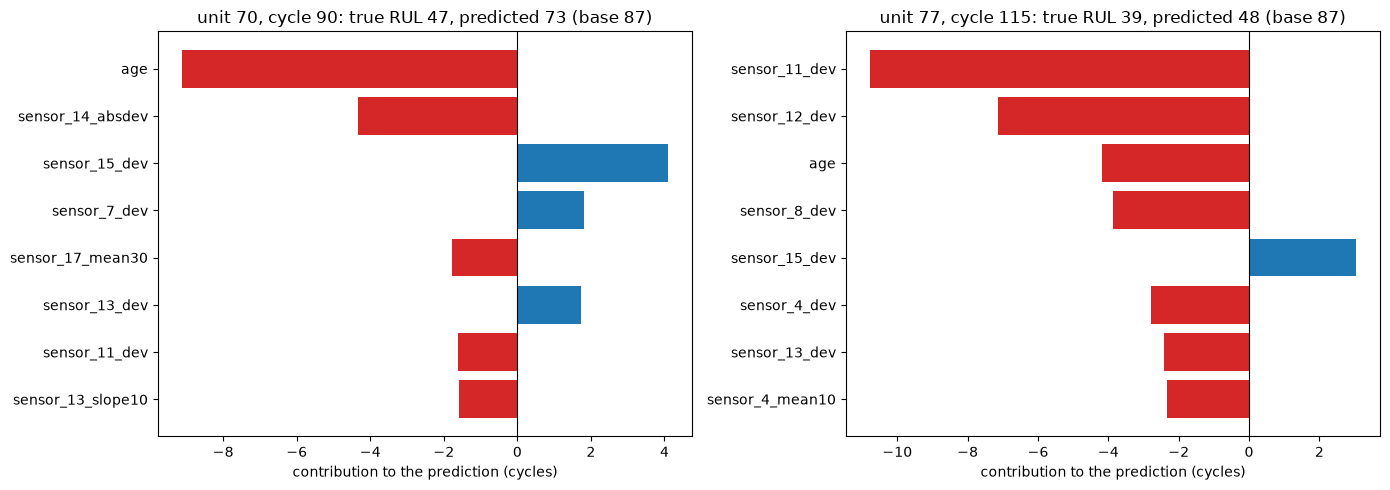

In [13]:
explainer = shap.TreeExplainer(model0)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (_, row) in zip(axes, picks.iterrows(), strict=True):
    sv = pd.Series(explainer.shap_values(row[FEATURES].to_frame().T.astype(float))[0], index=FEATURES)
    top = sv.reindex(sv.abs().nlargest(8).index)[::-1]
    ax.barh(top.index, top.values, color=["C3" if v < 0 else "C0" for v in top.values])
    ax.axvline(0, color="k", lw=0.8)
    ax.set(title=f"unit {int(row['unit'])}, cycle {int(row['cycle'])}: true RUL {row['rul_true']:.0f}, "
                 f"predicted {row['lgbm']:.0f} (base {explainer.expected_value:.0f})",
           xlabel="contribution to the prediction (cycles)")
plt.tight_layout()
plt.show()

**Reading.** Both engines the simpler models got most wrong are short-lived (137 and 154 cycles): by age they look young, so the clock gives them 110 and 85 cycles when they have 47 and 39. The linear model is not much better (94 and 83). LightGBM gets unit 77 almost right (48 for 39) and improves unit 70 without fixing it (73 for 47, still 26 cycles late).

The SHAP bars say why. For unit 77, the deviations of sensors 11 and 12 pull the prediction down by 11 and 7 cycles and age by 4: the sensors have seen the degradation. For unit 70, the largest contribution is age, pulling down by 9, while sensor 15's deviation pushes up by 4. At cycle 90 of a 137-cycle engine, the sensors that usually carry the signal have barely moved, and the model is leaning on age, which is exactly the information that misleads for a short-lived engine. These are the engines to watch in notebook 05: unusually short lives where degradation shows late, and where being late is the expensive error.

## 6. Logging the working model

The three models of this notebook join the `fd001-development` experiment next to the clock and the linear baseline from notebook 03. Logging now replaces earlier runs with the same name, so re-running a notebook updates its runs instead of adding duplicates.

In [14]:
import mlflow

from turbofan_rul.tracking import log_model_run, start_experiment

start_experiment("fd001-development")
logged = {
    "linear-99-features": (oof_rows(linear, FEATURES, Xf), {"model": "OLS", "features": "window:99", "prediction_clip": "0-125"}),
    "lgbm-99-features": (pred_lgbm, {"model": "LightGBM", "features": "window:99", "prediction_clip": "0-125", **LGBM_PARAMS}),
    "lgbm-40-features": (pred_pruned, {"model": "LightGBM", "features": "window:40:" + ",".join(PRUNED), "prediction_clip": "0-125", **LGBM_PARAMS}),
}
for run_name, (pred, params) in logged.items():
    scores = score_draws(pred)
    metrics = {"rmse_mean": scores["rmse"], "rmse_std": scores["rmse_std"], "phm08_per_100_mean": scores["phm08_per_100"],
               "fold_rmse_min": scores["fold_min"], "fold_rmse_max": scores["fold_max"], "n_draws": 30}
    preds = rows[["unit", "cycle", "fold", "rul_true"]].assign(pred=pred)
    log_model_run(run_name, params, metrics, predictions=preds, tags={"notebook": "04_features_and_boosting"})

runs = mlflow.search_runs(experiment_names=["fd001-development"])
runs[["tags.mlflow.runName", "metrics.rmse_mean", "metrics.phm08_per_100_mean"]].sort_values("metrics.rmse_mean").round(1)

,tags.mlflow.runName,metrics.rmse_mean,metrics.phm08_per_100_mean
0,lgbm-40-features,12.4,229.7
1,lgbm-99-features,12.7,238.8
2,linear-99-features,19.3,659.7
3,linear-12-sensors,25.0,1708.9
4,clock-weibull3-capped,32.0,7358.6


---

## Decisions

| # | Question | Decision | Evidence |
|---|----------|----------|----------|
| 1 | Feature set | Trailing window features per engine, in `features.py`: means (5, 10, 30), difference from the 30-cycle mean, slopes (10, 30), 30-cycle std, deviation of the 5-cycle mean from the engine's first-20-cycle baseline, absolute deviations for sensors 9 and 14, age. Pruned to the 40 features with permutation importance of at least 0.05 cycles | Section 2: slope30 and deviation carry the signal (linear model 25.0 to 19.5 and 20.0). Section 4a: pruned LightGBM 12.4 vs 12.7 with all 99 |
| 2 | Working model | LightGBM, settings in `config.py` (learning rate 0.03, 15 leaves, 50 rows per leaf, 80% subsampling), early stopping with 16 monitor engines per fold. RMSE 12.4, PHM08 230 per 100 on the pruned set | Section 3: beats the linear model on the same features (19.3) by three times the fold spread, and the clock (32.0) by far. Bias within 5 cycles below the cap |
| 3 | Knobs | Left at the base settings. 63/5 and 7/200 leaves per rows score within noise of the base | Section 3a |
| 4 | Loss | Squared error. Huber scores 17.6 and shifts the bias late (+3.7): it caps the gradient of exactly the residuals that matter. The loss is chosen against the cost in notebook 05 | Section 3a |
| 5 | Early stopping | Kept as a guard, though a fixed 2,000 trees with all 80 engines scores slightly better (12.4 vs 12.7) | Section 3 |
| 6 | Importance and explanation | Permutation importance on validation cuts decides pruning; SHAP explains individual predictions. Gain is reported but not used for decisions | Section 4: age is first by permutation with 2% of the gain |
| 7 | Leakage | Engine-wise folds only. A row-wise split inflates LightGBM from 12.7 to 10.1 | Section 3a |

Notes to carry into notebook 05 (asymmetric cost):

- The working model is unbiased below the cap and 21 cycles early above it, by construction of the label. The cost analysis has to decide whether the cap stays at 125.
- The worst remaining errors are short-lived engines where degradation shows late (unit 70: 26 cycles late at cycle 90). Those are the expensive errors under PHM08 and the scenario's costs, and the ones a quantile or asymmetric objective should move.
- Huber showed that the loss changes what the trees see. The notebook 05 objectives (quantile, custom asymmetric) are chosen against the scenario's costs, not against RMSE.
- The feature set for the pipeline is the 40-feature pruned set. `build_features` is leak-safe by construction and tested; the pipeline in level 8 computes features from the cycles revealed up to each Monday.
- Age is the single feature the model depends on most. For an engine that enters the fleet mid-life, age is unknown or approximate; the simulation has to say how such engines are handled.